# Practice Exercise — Solutions (Python)
## Publication-Quality Visualization Workshop

**Instructor:** Yuyan Yi  
**Date:** December 4, 2026

> Worked solutions for all 9 practice exercise options, in Python. These reuse the exact approaches taught in the main workshop session. Run the data-loading cell first, then jump to whichever option(s) you worked on.

## Load data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", font_scale=1.0)
colors = {"Control": "#440154", "Treatment": "#21908C"}

clinical_py = pd.read_csv("clinical_trial_data.csv")
longitudinal_py = pd.read_csv("longitudinal_data.csv")
pca_data_py = pd.read_csv("pca_data.csv")

clinical_py.head()

,patient_id,arm,age,sex,site,smoker,biomarker,baseline_score,followup_score,responder,response_label,time_months,event
0,PT-001,Control,72,Female,Site_4,Current,18.166616,62.558045,60.989192,0,No Response,17.369203,0
1,PT-002,Control,71,Female,Site_2,Never,8.929539,53.300996,43.011473,0,No Response,38.845020,0
2,PT-003,Control,46,Male,Site_2,Current,40.468521,62.919948,66.953718,0,No Response,11.674484,1
3,PT-004,Control,80,Female,Site_1,Former,12.001523,49.973288,44.155455,0,No Response,82.173169,1
4,PT-005,Treatment,50,Female,Site_2,Never,76.587441,57.754254,47.358360,0,No Response,66.918541,0


---

## Option 1: Table 1 comparing baseline characteristics by arm

In [3]:
from tableone import TableOne

columns = ["sex", "smoker", "site", "response_label", "baseline_score", "followup_score", "age", "biomarker"]
categorical = ["sex", "smoker", "response_label", "site"]

table1 = TableOne(
    clinical_py, columns=columns, categorical=categorical,
    groupby="arm", pval=True, htest_name=True
)

print(table1.tabulate(tablefmt="github"))

table1_raw = table1.tableone.copy()
table1_raw.index = table1_raw.index.set_names(["Characteristic", "Level"])
table1_df = table1_raw.reset_index()
table1_df.columns = [
    '_'.join([str(c) for c in col if c not in ('', 'Grouped by arm')]).strip('_')
    for col in table1_df.columns.to_flat_index()
]

table1_df.style.set_caption("Baseline Characteristics by Arm").format(escape="html")

|                           |             |   Missing | Overall     | Control     | Treatment   | P-Value   | Test           |
|---------------------------|-------------|-----------|-------------|-------------|-------------|-----------|----------------|
| n                         |             |           | 200         | 89          | 111         |           |                |
| sex, n (%)                | Female      |           | 107 (53.5)  | 46 (51.7)   | 61 (55.0)   | 0.750     | Chi-squared    |
|                           | Male        |           | 93 (46.5)   | 43 (48.3)   | 50 (45.0)   |           |                |
| smoker, n (%)             | Current     |           | 42 (21.0)   | 18 (20.2)   | 24 (21.6)   | 0.725     | Chi-squared    |
|                           | Former      |           | 54 (27.0)   | 22 (24.7)   | 32 (28.8)   |           |                |
|                           | Never       |           | 104 (52.0)  | 49 (55.1)   | 55 (49.5)   |           |  

,Characteristic,Level,Missing,Overall,Control,Treatment,P-Value,Test
0,n,,,200,89,111,,
1,"sex, n (%)",Female,,107 (53.5),46 (51.7),61 (55.0),0.750,Chi-squared
2,"sex, n (%)",Male,,93 (46.5),43 (48.3),50 (45.0),,
3,"smoker, n (%)",Current,,42 (21.0),18 (20.2),24 (21.6),0.725,Chi-squared
4,"smoker, n (%)",Former,,54 (27.0),22 (24.7),32 (28.8),,
5,"smoker, n (%)",Never,,104 (52.0),49 (55.1),55 (49.5),,
6,"site, n (%)",Site_1,,49 (24.5),16 (18.0),33 (29.7),0.284,Chi-squared
7,"site, n (%)",Site_2,,50 (25.0),25 (28.1),25 (22.5),,
8,"site, n (%)",Site_3,,56 (28.0),27 (30.3),29 (26.1),,
9,"site, n (%)",Site_4,,45 (22.5),21 (23.6),24 (21.6),,


---

## Option 2: Density plot or ridgeline plot

Showing both — overlaid density by arm, and ridgeline by site.

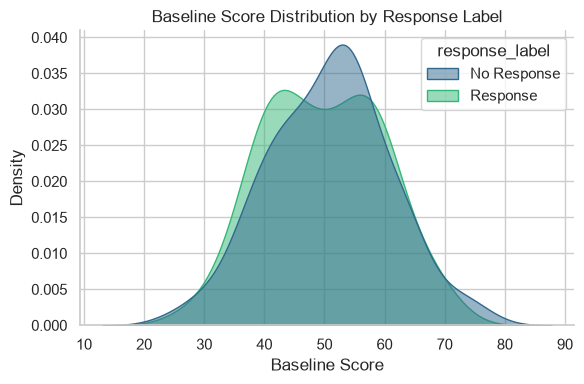

In [11]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.kdeplot(data=clinical_py, x="baseline_score", hue="response_label", fill=True,
            common_norm=False, alpha=0.5, palette="viridis", ax=ax)
ax.set_xlabel("Baseline Score")
ax.set_ylabel("Density")
ax.set_title("Baseline Score Distribution by Response Label")
sns.despine()
plt.tight_layout()
plt.show()

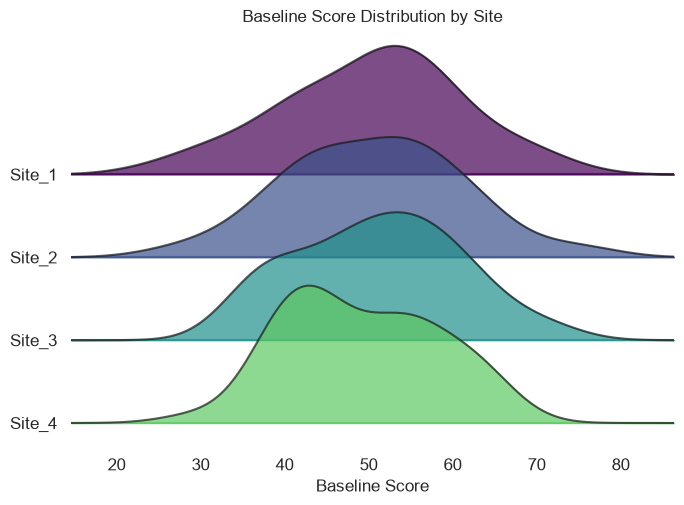

In [12]:
import joypy

fig, axes = joypy.joyplot(
    clinical_py, by="site", column="baseline_score",
    colormap=plt.cm.viridis, alpha=0.7, figsize=(7, 5),
    title="Baseline Score Distribution by Site"
)
plt.xlabel("Baseline Score")
plt.show()

---

## Option 3: Kaplan-Meier curve with risk table

`lifelines` doesn't have a one-line built-in risk table the way R's `survminer` does; this shows a standard approach of adding a risk-count table manually underneath the curve using `lifelines`' `add_at_risk_counts` helper.

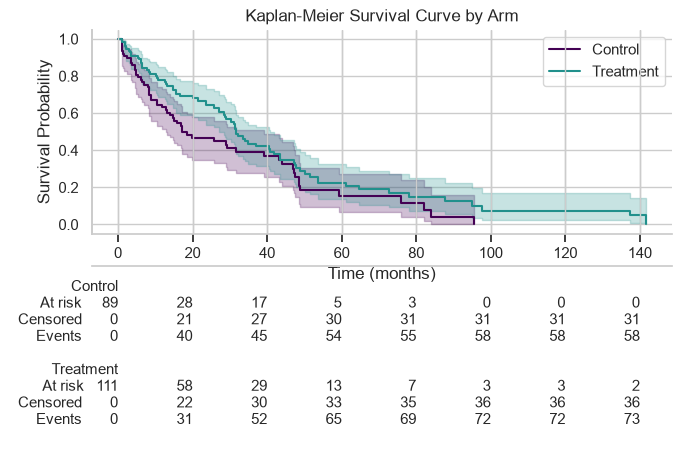

Log-rank p-value: 0.0490


In [13]:
from lifelines import KaplanMeierFitter
from lifelines.plotting import add_at_risk_counts
from lifelines.statistics import logrank_test

fig, ax = plt.subplots(figsize=(7, 5))
fitters = []

for arm, color in colors.items():
    mask = clinical_py["arm"] == arm
    kmf = KaplanMeierFitter()
    kmf.fit(clinical_py.loc[mask, "time_months"], clinical_py.loc[mask, "event"], label=arm)
    kmf.plot_survival_function(ax=ax, color=color, ci_show=True)
    fitters.append(kmf)

ax.set_xlabel("Time (months)")
ax.set_ylabel("Survival Probability")
ax.set_title("Kaplan-Meier Survival Curve by Arm")
add_at_risk_counts(*fitters, ax=ax)
sns.despine()
plt.tight_layout()
plt.show()

ctrl = clinical_py[clinical_py.arm == "Control"]
trt = clinical_py[clinical_py.arm == "Treatment"]
result = logrank_test(ctrl.time_months, trt.time_months,
                       event_observed_A=ctrl.event, event_observed_B=trt.event)
print(f"Log-rank p-value: {result.p_value:.4f}")

---

## Option 4: Forest plot across 3+ subgroups

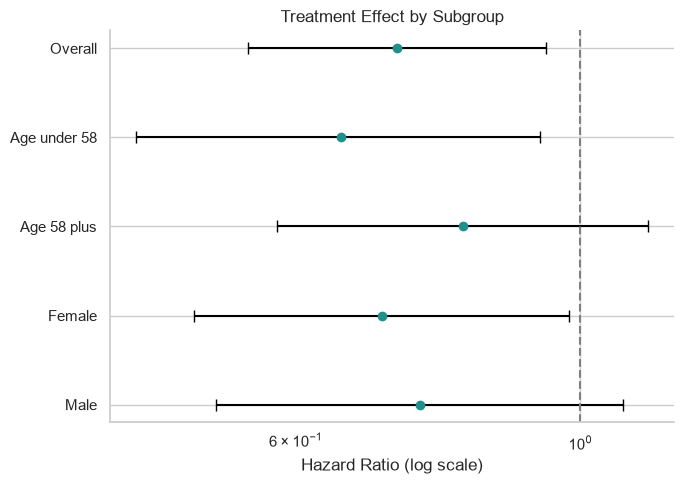

In [14]:
forest_data_py = pd.DataFrame({
    "subgroup": ["Overall", "Age under 58", "Age 58 plus", "Female", "Male"],
    "hr": [0.72, 0.65, 0.81, 0.70, 0.75],
    "lower": [0.55, 0.45, 0.58, 0.50, 0.52],
    "upper": [0.94, 0.93, 1.13, 0.98, 1.08],
})

fig, ax = plt.subplots(figsize=(7, 5))
y_pos = np.arange(len(forest_data_py))

ax.errorbar(
    forest_data_py["hr"], y_pos,
    xerr=[forest_data_py["hr"] - forest_data_py["lower"],
          forest_data_py["upper"] - forest_data_py["hr"]],
    fmt="o", color="#21908C", ecolor="black", capsize=4
)
ax.axvline(x=1, linestyle="--", color="gray")
ax.set_xscale("log")
ax.set_yticks(y_pos)
ax.set_yticklabels(forest_data_py["subgroup"])
ax.invert_yaxis()
ax.set_xlabel("Hazard Ratio (log scale)")
ax.set_title("Treatment Effect by Subgroup")
sns.despine()
plt.tight_layout()
plt.show()

---

## Option 5: ROC curve with AUC

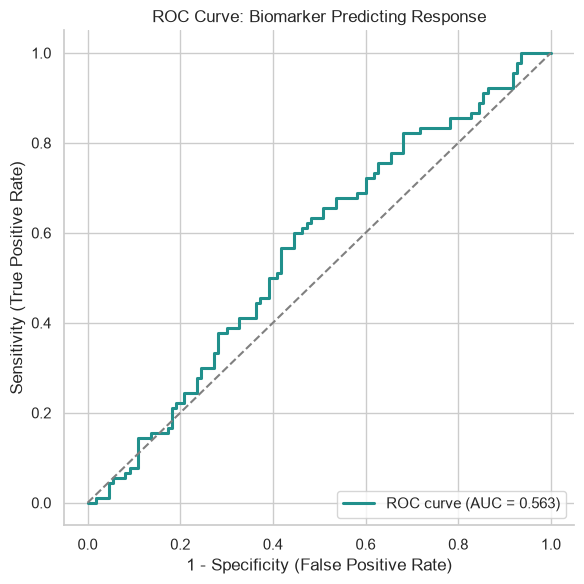

In [15]:
from sklearn.metrics import roc_curve, auc

fpr, tpr, thresholds = roc_curve(clinical_py["responder"], clinical_py["biomarker"])
roc_auc = auc(fpr, tpr)

fig, ax = plt.subplots(figsize=(6, 6))
ax.plot(fpr, tpr, color="#21908C", linewidth=2.2, label=f"ROC curve (AUC = {roc_auc:.3f})")
ax.plot([0, 1], [0, 1], linestyle="--", color="gray")
ax.set_xlabel("1 - Specificity (False Positive Rate)")
ax.set_ylabel("Sensitivity (True Positive Rate)")
ax.set_title("ROC Curve: Biomarker Predicting Response")
ax.legend(loc="lower right")
sns.despine()
plt.tight_layout()
plt.show()

---

## Option 6: Line chart of score trajectory with error bars

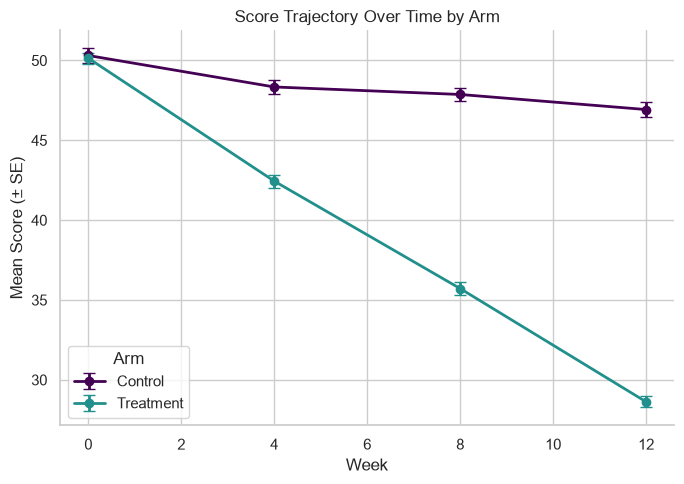

In [16]:
summary_py = (
    longitudinal_py.groupby(["arm", "week"])["score"]
    .agg(mean_score="mean", sd_score="std", n="count")
    .reset_index()
)
summary_py["se_score"] = summary_py["sd_score"] / np.sqrt(summary_py["n"])

fig, ax = plt.subplots(figsize=(7, 5))

for arm, color in colors.items():
    sub = summary_py[summary_py.arm == arm]
    ax.errorbar(sub["week"], sub["mean_score"], yerr=sub["se_score"],
                marker="o", capsize=4, label=arm, color=color, linewidth=2)

ax.set_xlabel("Week")
ax.set_ylabel("Mean Score (± SE)")
ax.set_title("Score Trajectory Over Time by Arm")
ax.legend(title="Arm")
sns.despine()
plt.tight_layout()
plt.show()

---

## Option 7: Annotated boxplot/mean±SD bar comparing scores across site

Showing the ANOVA + pairwise comparison version across `site`, with significance brackets, since this directly addresses "comparing scores across site."

ANOVA p-value: 0.8108
Multiple Comparison of Means - Tukey HSD, FWER=0.05
group1 group2 meandiff p-adj   lower  upper  reject
---------------------------------------------------
Site_1 Site_2   0.2916 0.9989 -4.8832 5.4664  False
Site_1 Site_3   0.7692 0.9789 -4.2666 5.8049  False
Site_1 Site_4  -1.1318  0.946 -6.4469 4.1834  False
Site_2 Site_3   0.4776 0.9947 -4.5312 5.4863  False
Site_2 Site_4  -1.4234  0.898  -6.713 3.8663  False
Site_3 Site_4  -1.9009 0.7746 -7.0546 3.2528  False
---------------------------------------------------


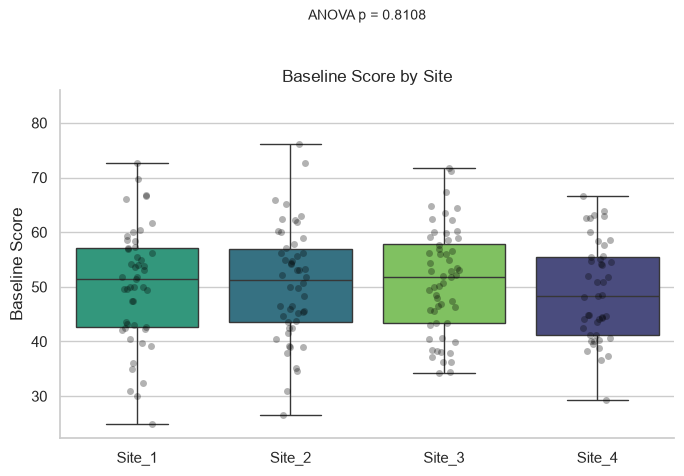

In [17]:
from scipy.stats import f_oneway
from statsmodels.stats.multicomp import pairwise_tukeyhsd

sites = sorted(clinical_py["site"].unique())
site_groups = [clinical_py.loc[clinical_py.site == s, "baseline_score"] for s in sites]

f_stat, anova_p = f_oneway(*site_groups)
print(f"ANOVA p-value: {anova_p:.4f}")

tukey = pairwise_tukeyhsd(endog=clinical_py["baseline_score"], groups=clinical_py["site"], alpha=0.05)
print(tukey.summary())

tukey_df = pd.DataFrame(data=tukey._results_table.data[1:], columns=tukey._results_table.data[0])

def p_to_stars(p):
    if p < 0.001: return "***"
    elif p < 0.01: return "**"
    elif p < 0.05: return "*"
    else: return None

fig, ax = plt.subplots(figsize=(7, 5))
order = sites

sns.boxplot(data=clinical_py, x="site", y="baseline_score", order=order, hue="site", palette="viridis", legend=False, ax=ax)
sns.stripplot(data=clinical_py, x="site", y="baseline_score", order=order, color="black", alpha=0.3, ax=ax)

y_max = clinical_py["baseline_score"].max()
ax.text((len(order) - 1) / 2, y_max * 1.3, f"ANOVA p = {anova_p:.4f}", ha="center", fontsize=10)

bracket_y = y_max * 1.05
step = y_max * 0.08
for _, row in tukey_df.iterrows():
    stars = p_to_stars(row["p-adj"])
    if stars is None:
        continue
    i, j = order.index(row["group1"]), order.index(row["group2"])
    ax.plot([i, i, j, j], [bracket_y, bracket_y+step*0.2, bracket_y+step*0.2, bracket_y], lw=1, color="black")
    ax.text((i+j)/2, bracket_y + step*0.25, stars, ha="center", fontsize=12)
    bracket_y += step

_ = ax.set_xlabel(None)
_ = ax.set_ylabel("Baseline Score")
_ = ax.set_title("Baseline Score by Site")
_ = ax.set_ylim(top=bracket_y + step)
sns.despine()
plt.tight_layout()
plt.show()

---

## Option 8: Stacked bar chart of smoker status by site

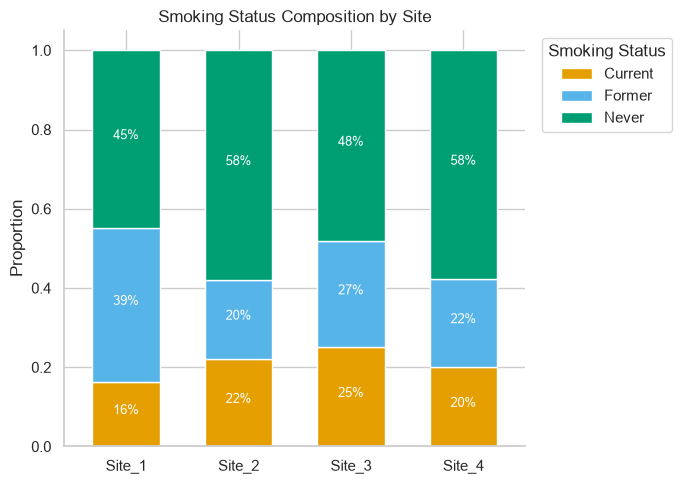

In [18]:
smoker_summary_py = (
    clinical_py.groupby(["site", "smoker"]).size()
    .unstack()
)
smoker_summary_py = smoker_summary_py.div(smoker_summary_py.sum(axis=1), axis=0)

okabe_ito_three = ["#E69F00", "#56B4E9", "#009E73"]
fig, ax = plt.subplots(figsize=(7, 5))
smoker_summary_py.plot(kind="bar", stacked=True, color=okabe_ito_three, ax=ax, width=0.6)

for i, site in enumerate(smoker_summary_py.index):
    cumulative = 0
    for col in smoker_summary_py.columns:
        val = smoker_summary_py.loc[site, col]
        _ = ax.text(i, cumulative + val / 2, f"{val:.0%}", ha="center", color="white", fontsize=9)
        cumulative += val

_ = ax.set_xlabel(None)
_ = ax.set_ylabel("Proportion")
_ = ax.set_title("Smoking Status Composition by Site")
_ = ax.legend(title="Smoking Status", bbox_to_anchor=(1.02, 1), loc="upper left")
_ = ax.set_xticklabels(smoker_summary_py.index, rotation=0)
sns.despine()
plt.tight_layout()
plt.show()

**Note:** this uses a 3-category version of the stacked bar chart taught in the main workshop (which used 2 categories: Response/No Response). With 3 categories, stacking is still readable; beyond ~4 categories, consider a grouped bar chart instead.

---

## Option 9: PCA score plot or biplot of the biomarker panel

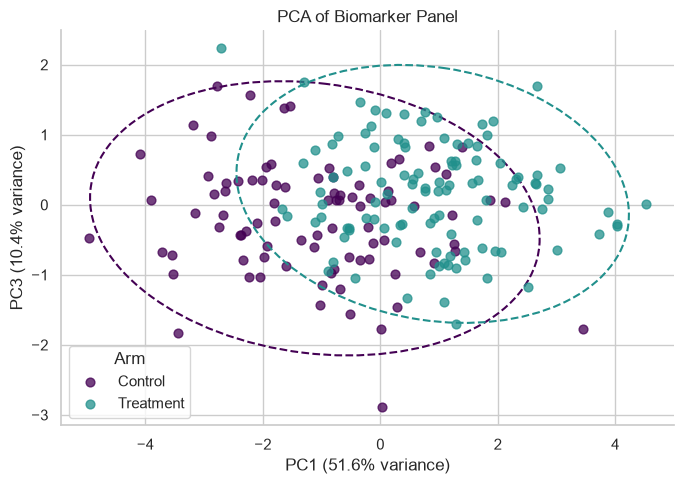

In [28]:
import numpy as np
from scipy.stats import chi2
from matplotlib.patches import Ellipse
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

def add_confidence_ellipse(x, y, ax, level=0.95, **kwargs):
    """Draw a covariance ellipse containing `level` of a bivariate normal."""
    if len(x) < 3:
        return
    cov = np.cov(x, y)
    eigvals, eigvecs = np.linalg.eigh(cov)
    order = eigvals.argsort()[::-1]
    eigvals, eigvecs = eigvals[order], eigvecs[:, order]

    angle = np.degrees(np.arctan2(eigvecs[1, 0], eigvecs[0, 0]))
    scale = np.sqrt(chi2.ppf(level, df=2))
    width, height = 2 * scale * np.sqrt(eigvals)

    ax.add_patch(Ellipse(xy=(np.mean(x), np.mean(y)), width=width, height=height,
                         angle=angle, fill=False, **kwargs))

biomarker_cols = [f"marker_{i}" for i in range(1, 7)]
X = pca_data_py[biomarker_cols].values
X_scaled = StandardScaler().fit_transform(X)

pca = PCA(n_components=3)
pc_scores = pca.fit_transform(X_scaled)
var_explained = pca.explained_variance_ratio_ * 100

pc_df = pd.DataFrame(pc_scores, columns=["PC1", "PC2", "PC3"])
pc_df["arm"] = pca_data_py["arm"].values

fig, ax = plt.subplots(figsize=(7, 5))
for arm_name, color in colors.items():
    sub = pc_df[pc_df.arm == arm_name]
    ax.scatter(sub["PC1"], sub["PC3"], color=color, alpha=0.75, s=40, label=arm_name)
    add_confidence_ellipse(sub["PC1"].values, sub["PC3"].values, ax,
                           level=0.95, edgecolor=color, linewidth=1.5, linestyle="--")

_ = ax.set_xlabel(f"PC1 ({var_explained[0]:.1f}% variance)")
_ = ax.set_ylabel(f"PC3 ({var_explained[2]:.1f}% variance)")
_ = ax.set_title("PCA of Biomarker Panel")
ax.legend(title="Arm")
ax.autoscale_view()
sns.despine()
plt.tight_layout()
plt.show()

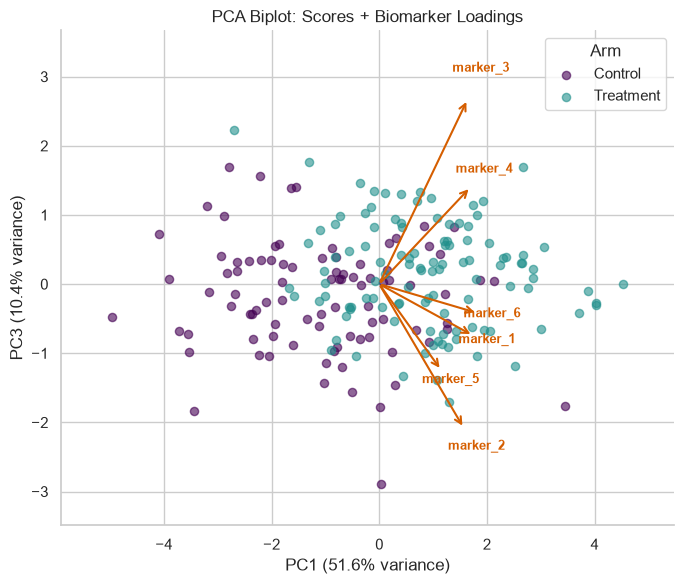

In [30]:
loadings = pca.components_.T[:, :3]
scale_factor = np.abs(pc_scores).max() * 0.8

fig, ax = plt.subplots(figsize=(7, 6))

for arm_name, color in colors.items():
    sub = pc_df[pc_df.arm == arm_name]
    ax.scatter(sub["PC1"], sub["PC3"], color=color, alpha=0.6, s=35, label=arm_name)

arrow_endpoints_x = []
arrow_endpoints_y = []

for i, marker_name in enumerate(biomarker_cols):
    x_end = loadings[i, 0] * scale_factor
    y_end = loadings[i, 2] * scale_factor

    ax.annotate("", xy=(x_end, y_end), xytext=(0, 0),
                arrowprops=dict(arrowstyle="->", color="#D55E00", lw=1.5))
    label_x, label_y = x_end * 1.15, y_end * 1.15
    ax.text(label_x, label_y, marker_name, color="#D55E00", fontsize=9, fontweight="bold", ha="center")

    arrow_endpoints_x.append(label_x)
    arrow_endpoints_y.append(label_y)

all_x = list(pc_df["PC1"]) + arrow_endpoints_x
all_y = list(pc_df["PC3"]) + arrow_endpoints_y
x_margin = (max(all_x) - min(all_x)) * 0.1
y_margin = (max(all_y) - min(all_y)) * 0.1
_ = ax.set_xlim(min(all_x) - x_margin, max(all_x) + x_margin)
_ = ax.set_ylim(min(all_y) - y_margin, max(all_y) + y_margin)

_ = ax.set_xlabel(f"PC1 ({var_explained[0]:.1f}% variance)")
_ = ax.set_ylabel(f"PC3 ({var_explained[2]:.1f}% variance)")
_ = ax.set_title("PCA Biplot: Scores + Biomarker Loadings")
ax.legend(title="Arm")
sns.despine()
plt.tight_layout()
plt.show()